# Exploratory Data Analysis of Spotify Songs

**Goal:** Analyze Spotify track popularity, audio features, genres, and duration.

**Dataset:** Spotify Tracks Dataset (`dataset.csv` inside the uploaded ZIP).

This notebook is written to run in Google Colab or Jupyter. Upload `dataset.csv` when prompted, or upload `archive.zip` and extract it first.


In [3]:
import os
import zipfile
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
# If using local Jupyter, remove the above imports and set csv_path manually.
csv_path = r"C:\Users\Aishwarya R Patil\Downloads\archive\dataset.csv"

sns.set_theme(style="whitegrid")


## 1. Load the dataset

In [4]:
df = pd.read_csv(csv_path)
print("Shape:", df.shape)
display(df.head())


Shape: (114000, 21)


,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


## 2. Understand columns and data quality

In [5]:
print("Rows, columns:", df.shape)
print("\\nColumn names:")
print(df.columns.tolist())
print("\\nData types:")
display(df.dtypes.to_frame("dtype"))
print("\\nMissing values:")
display(df.isna().sum().sort_values(ascending=False).to_frame("missing_count"))
print("\\nExact duplicate rows:", df.duplicated().sum())
print("Duplicate track_id rows:", df["track_id"].duplicated().sum())
display(df.describe(include="all").T)


Rows, columns: (114000, 21)
\nColumn names:
['Unnamed: 0', 'track_id', 'artists', 'album_name', 'track_name', 'popularity', 'duration_ms', 'explicit', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature', 'track_genre']
\nData types:


,dtype
Unnamed: 0,int64
track_id,object
artists,object
album_name,object
track_name,object
popularity,int64
duration_ms,int64
explicit,bool
danceability,float64
energy,float64


\nMissing values:


,missing_count
artists,1
track_name,1
album_name,1
Unnamed: 0,0
track_id,0
popularity,0
duration_ms,0
explicit,0
danceability,0
energy,0


\nExact duplicate rows: 0
Duplicate track_id rows: 24259


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Unnamed: 0,114000.0,NaN,NaN,NaN,56999.5,32909.109681,0.0,28499.75,56999.5,85499.25,113999.0
track_id,114000,89741,6S3JlDAGk3uu3NtZbPnuhS,9,NaN,NaN,NaN,NaN,NaN,NaN,NaN
artists,113999,31437,The Beatles,279,NaN,NaN,NaN,NaN,NaN,NaN,NaN
album_name,113999,46589,Alternative Christmas 2022,195,NaN,NaN,NaN,NaN,NaN,NaN,NaN
track_name,113999,73608,Run Rudolph Run,151,NaN,NaN,NaN,NaN,NaN,NaN,NaN
popularity,114000.0,NaN,NaN,NaN,33.238535,22.305078,0.0,17.0,35.0,50.0,100.0
duration_ms,114000.0,NaN,NaN,NaN,228029.153114,107297.712645,0.0,174066.0,212906.0,261506.0,5237295.0
explicit,114000,2,False,104253,NaN,NaN,NaN,NaN,NaN,NaN,NaN
danceability,114000.0,NaN,NaN,NaN,0.5668,0.173542,0.0,0.456,0.58,0.695,0.985
energy,114000.0,NaN,NaN,NaN,0.641383,0.251529,0.0,0.472,0.685,0.854,1.0


## 3. Clean and prepare data

In [6]:
# Keep a raw copy so cleaning decisions remain transparent.
data = df.copy()

# This column appears to be a row index, not a meaningful feature.
if "Unnamed: 0" in data.columns:
    data = data.drop(columns=["Unnamed: 0"])

# Convert milliseconds to minutes for easier interpretation.
data["duration_min"] = data["duration_ms"] / 60000

# There are a few missing artist/album/track names. Keep the rows for numeric analysis;
# fill text fields only for display or grouping if needed.
for col in ["artists", "album_name", "track_name"]:
    if col in data.columns:
        data[col] = data[col].fillna("Unknown")

print("Prepared shape:", data.shape)
print("Rows with duration <= 0:", (data["duration_ms"] <= 0).sum())
print("Rows longer than 15 minutes:", (data["duration_min"] > 15).sum())
print("Popularity score = 0:", (data["popularity"] == 0).sum())


Prepared shape: (114000, 21)
Rows with duration <= 0: 1
Rows longer than 15 minutes: 153
Popularity score = 0: 16020


## 4. Descriptive statistics

In [7]:
display(data[["popularity", "duration_min", "danceability", "energy",
               "loudness", "speechiness", "acousticness", "instrumentalness",
               "liveness", "valence", "tempo"]].describe().T.round(3))
print("Mean popularity:", round(data["popularity"].mean(), 2))
print("Median popularity:", round(data["popularity"].median(), 2))
print("Mean duration (minutes):", round(data["duration_min"].mean(), 2))
print("Median duration (minutes):", round(data["duration_min"].median(), 2))


,count,mean,std,min,25%,50%,75%,max
popularity,114000.0,33.239,22.305,0.000,17.000,35.000,50.000,100.000
duration_min,114000.0,3.800,1.788,0.000,2.901,3.548,4.358,87.288
danceability,114000.0,0.567,0.174,0.000,0.456,0.580,0.695,0.985
energy,114000.0,0.641,0.252,0.000,0.472,0.685,0.854,1.000
loudness,114000.0,-8.259,5.029,-49.531,-10.013,-7.004,-5.003,4.532
speechiness,114000.0,0.085,0.106,0.000,0.036,0.049,0.084,0.965
acousticness,114000.0,0.315,0.333,0.000,0.017,0.169,0.598,0.996
instrumentalness,114000.0,0.156,0.310,0.000,0.000,0.000,0.049,1.000
liveness,114000.0,0.214,0.190,0.000,0.098,0.132,0.273,1.000
valence,114000.0,0.474,0.259,0.000,0.260,0.464,0.683,0.995


Mean popularity: 33.24
Median popularity: 35.0
Mean duration (minutes): 3.8
Median duration (minutes): 3.55


## 5. Popularity and duration distributions

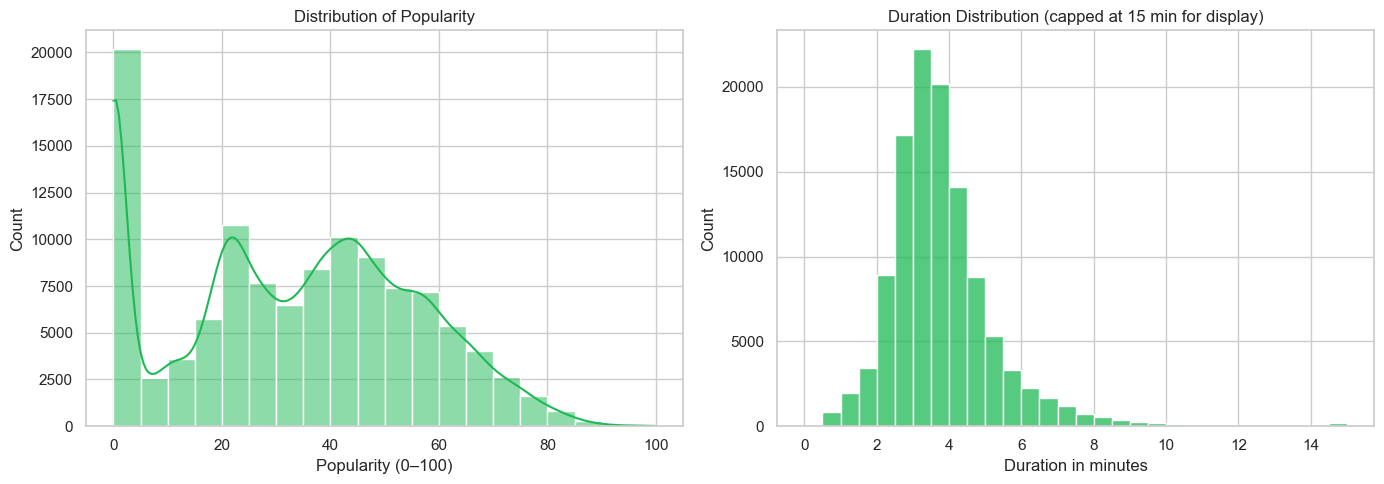

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(data["popularity"], bins=20, kde=True, ax=axes[0], color="#1DB954")
axes[0].set_title("Distribution of Popularity")
axes[0].set_xlabel("Popularity (0–100)")
sns.histplot(data["duration_min"].clip(upper=15), bins=30, ax=axes[1], color="#1DB954")
axes[1].set_title("Duration Distribution (capped at 15 min for display)")
axes[1].set_xlabel("Duration in minutes")
plt.tight_layout()
plt.show()


## 6. Compare genres

,tracks,avg_popularity,avg_danceability,avg_energy,avg_duration_min
track_genre,,,,,
pop-film,1000,59.28,0.60,0.60,4.66
k-pop,1000,56.90,0.65,0.68,4.19
chill,1000,53.65,0.66,0.43,2.82
sad,1000,52.38,0.69,0.46,2.56
grunge,1000,49.59,0.46,0.80,3.93
indian,1000,49.54,0.59,0.57,4.09
anime,1000,48.77,0.54,0.67,3.50
emo,1000,48.13,0.60,0.67,3.16
sertanejo,1000,47.87,0.59,0.71,3.41


,tracks,avg_popularity,avg_danceability,avg_energy,avg_duration_min
track_genre,,,,,
iranian,1000,2.21,0.30,0.55,5.33
romance,1000,3.24,0.43,0.29,3.34
latin,1000,8.30,0.72,0.73,3.56
detroit-techno,1000,11.17,0.72,0.71,6.20
chicago-house,1000,12.34,0.77,0.73,6.11
classical,1000,13.06,0.38,0.19,3.88
jazz,1000,13.63,0.51,0.35,3.17
grindcore,1000,14.62,0.27,0.92,2.23
kids,1000,14.89,0.78,0.61,2.61


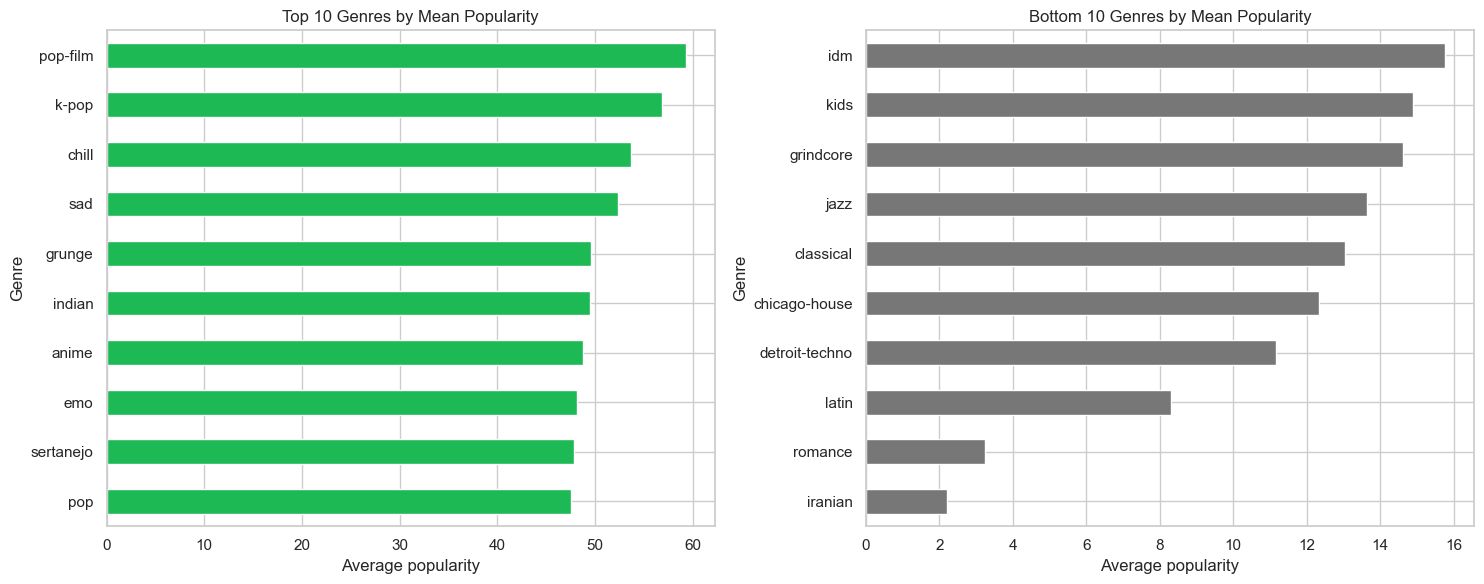

In [9]:
genre_summary = data.groupby("track_genre").agg(
    tracks=("track_id", "size"),
    avg_popularity=("popularity", "mean"),
    avg_danceability=("danceability", "mean"),
    avg_energy=("energy", "mean"),
    avg_duration_min=("duration_min", "mean")
).sort_values("avg_popularity", ascending=False)

display(genre_summary.head(10).round(2))
display(genre_summary.tail(10).sort_values("avg_popularity").round(2))

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
genre_summary.head(10).sort_values("avg_popularity").plot(
    kind="barh", y="avg_popularity", legend=False, ax=axes[0], color="#1DB954")
axes[0].set_title("Top 10 Genres by Mean Popularity")
axes[0].set_xlabel("Average popularity")
axes[0].set_ylabel("Genre")
genre_summary.tail(10).sort_values("avg_popularity").plot(
    kind="barh", y="avg_popularity", legend=False, ax=axes[1], color="#777777")
axes[1].set_title("Bottom 10 Genres by Mean Popularity")
axes[1].set_xlabel("Average popularity")
axes[1].set_ylabel("Genre")
plt.tight_layout()
plt.show()


## 7. Audio features vs popularity

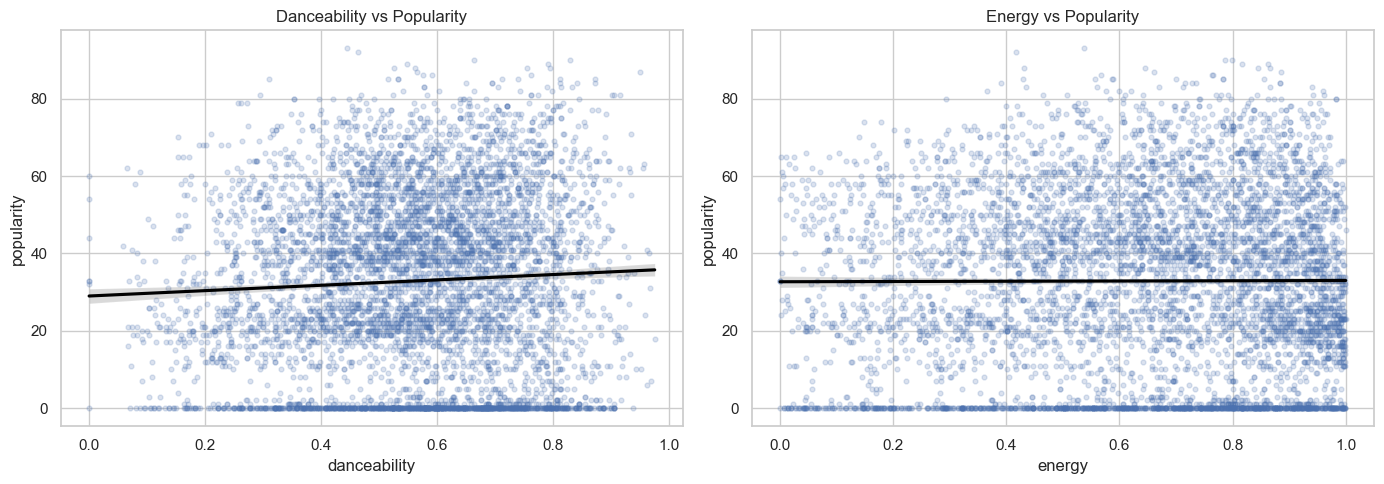

Correlation of popularity with danceability: 0.035
Correlation of popularity with energy: 0.001
Correlation of popularity with loudness: 0.050
Correlation of popularity with instrumentalness: -0.095
Correlation of popularity with speechiness: -0.045
Correlation of popularity with valence: -0.041


In [10]:
sample = data.sample(n=min(6000, len(data)), random_state=42)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.regplot(data=sample, x="danceability", y="popularity",
            scatter_kws={"alpha": 0.2, "s": 12}, line_kws={"color": "black"}, ax=axes[0])
axes[0].set_title("Danceability vs Popularity")
sns.regplot(data=sample, x="energy", y="popularity",
            scatter_kws={"alpha": 0.2, "s": 12}, line_kws={"color": "black"}, ax=axes[1])
axes[1].set_title("Energy vs Popularity")
plt.tight_layout()
plt.show()

for feature in ["danceability", "energy", "loudness", "instrumentalness", "speechiness", "valence"]:
    print(f"Correlation of popularity with {feature}: {data['popularity'].corr(data[feature]):.3f}")


## 8. Correlation heatmap

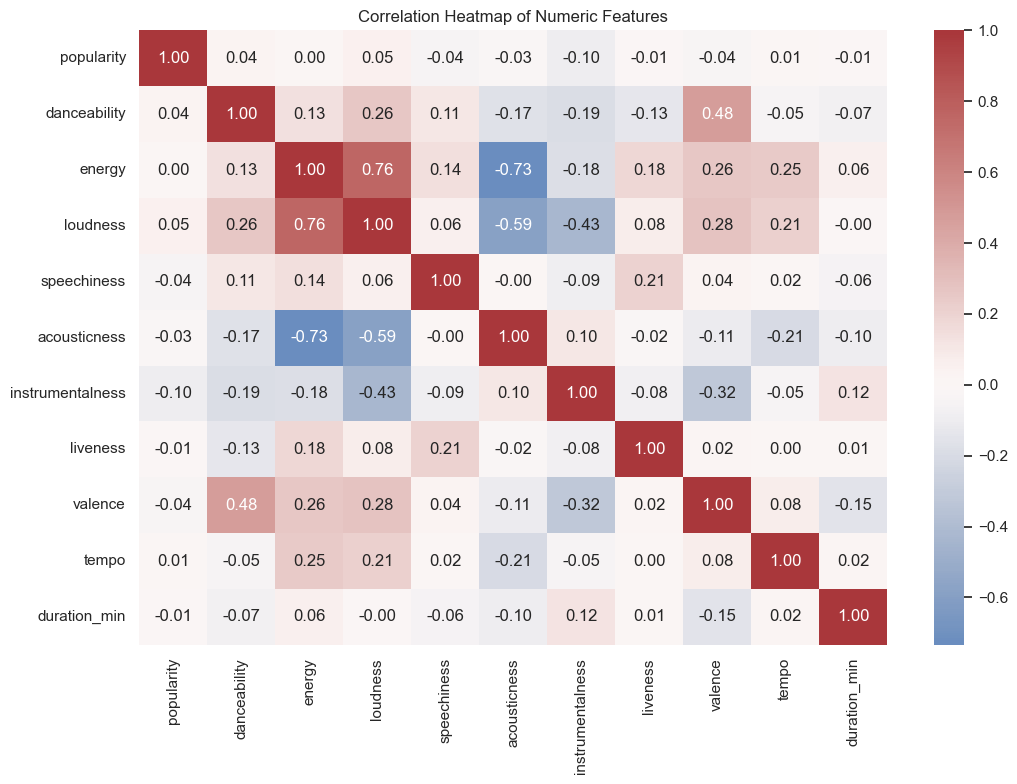

In [11]:
numeric_cols = ["popularity", "danceability", "energy", "loudness",
                "speechiness", "acousticness", "instrumentalness",
                "liveness", "valence", "tempo", "duration_min"]
corr = data[numeric_cols].corr()
plt.figure(figsize=(11, 8))
sns.heatmap(corr, cmap="vlag", center=0, annot=True, fmt=".2f")
plt.title("Correlation Heatmap of Numeric Features")
plt.tight_layout()
plt.show()


## 9. Explicit vs non-explicit tracks

,tracks,avg_popularity,median_popularity,avg_energy,avg_danceability
explicit,,,,,
False,104253,32.94,34.0,0.63,0.56
True,9747,36.45,37.0,0.72,0.64


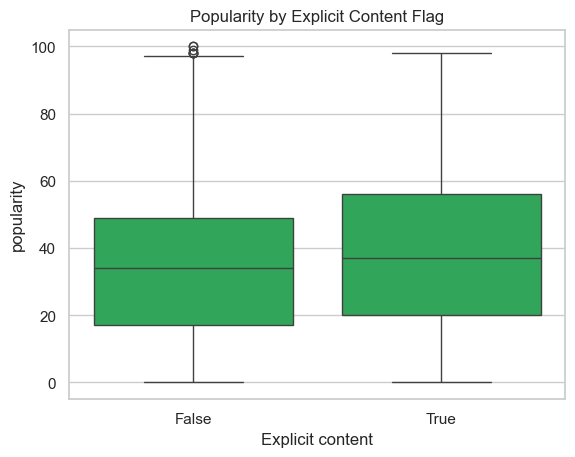

In [12]:
explicit_summary = data.groupby("explicit").agg(
    tracks=("track_id", "size"),
    avg_popularity=("popularity", "mean"),
    median_popularity=("popularity", "median"),
    avg_energy=("energy", "mean"),
    avg_danceability=("danceability", "mean")
)
display(explicit_summary.round(2))

sns.boxplot(data=data, x="explicit", y="popularity", color="#1DB954")
plt.title("Popularity by Explicit Content Flag")
plt.xlabel("Explicit content")
plt.show()


## 10. Conclusions and limitations

In [13]:
# Print key facts directly from the data so they can be cited in your report.
print(f"Dataset size: {data.shape[0]:,} rows")
print(f"Genres: {data['track_genre'].nunique()}")
print(f"Mean popularity: {data['popularity'].mean():.2f}")
print(f"Median popularity: {data['popularity'].median():.2f}")
print(f"Mean duration: {data['duration_min'].mean():.2f} minutes")
print(f"Median duration: {data['duration_min'].median():.2f} minutes")
print("Exact duplicate rows:", data.duplicated().sum())
print("Repeated track_id rows:", data["track_id"].duplicated().sum())


Dataset size: 114,000 rows
Genres: 114
Mean popularity: 33.24
Median popularity: 35.00
Mean duration: 3.80 minutes
Median duration: 3.55 minutes
Exact duplicate rows: 450
Repeated track_id rows: 24259


### Interpretation guide
- A correlation close to 0 indicates little **linear** relationship, not necessarily no relationship of any kind.
- Genre average popularity is descriptive of this dataset snapshot and is not proof that a genre is universally more popular.
- Repeated `track_id` values appear in the data. Do not blindly delete them before genre analysis, because a track may be represented under more than one genre label.
- Popularity can change over time and may depend on artist recognition, playlists, release timing, marketing, and many factors beyond audio features.
- Do not claim causation from these plots.
